 # for determining time bins - not sure where the mimic code is, so rewriting for choc

In [1]:
import numpy as np
import pandas as pd
import h5py
import os
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import importlib

import torch

# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.data.data_processor_for_shards as dpfs

# SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/terminal_reward_zero_dose_advantage"
# os.makedirs(SAVE_DIR, exist_ok=True)

In [2]:
data_dir = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set"
filenames = ['train.h5', 'val.h5', 'test.h5']

In [3]:
max_traj_length = 60*24
print(f"Max trajectory length: {max_traj_length} time steps ({max_traj_length/24:.1f} days)")

Max trajectory length: 1440 time steps (60.0 days)


In [11]:
with h5py.File(os.path.join(data_dir, 'train.h5'), 'r') as f:
    # convert feature_names from bytes to strings
    feature_names = [f['feature_names'][i].decode('utf-8') for i in range(len(f['feature_names']))]                
    stay_ids = f['stay_ids'][:]
    index_ptr = f['index_ptr'][:]
    trajectories = f['trajectories'][:]           

print(f"number of trajectories: {len(index_ptr)-1}")

number of trajectories: 7606


In [12]:
stay_ids.shape

(7606,)

In [13]:
def filter_by_stay_ids(stay_ids, index_ptr, trajectories, stay_ids_to_keep):

    print("number of stay_ids before filtering:", len(stay_ids))

    # Create boolean mask for stays to keep
    mask = np.isin(stay_ids, list(stay_ids_to_keep))
    indices_to_keep = np.where(mask)[0]
    new_stay_ids = stay_ids[indices_to_keep]
    
    print("number of stay_ids after filtering:", len(indices_to_keep))

    traj_mask = np.zeros(trajectories.shape[0], dtype=bool)
    for i in indices_to_keep:
        start_idx = index_ptr[i]
        end_idx = index_ptr[i+1]
        traj_mask[start_idx:end_idx] = True

    new_trajectories = trajectories[traj_mask]

    # Rebuild index_ptr
    new_index_ptr = np.zeros(len(indices_to_keep) + 1, dtype=np.int32)
    for i, idx in enumerate(indices_to_keep):
        start_idx = index_ptr[idx]
        end_idx = index_ptr[idx + 1]
        new_index_ptr[i + 1] = new_index_ptr[i] + (end_idx - start_idx)


    return new_stay_ids, new_index_ptr, new_trajectories


In [18]:
# load sepsis cohort and filter
sepsis_cohort_file = "/home/jake/Documents/AI_Clinician/choc_data/cohorts/sepsis/stay_ids.csv"
sepsis_stay_ids = pd.read_csv(sepsis_cohort_file)['stay_id'].tolist()

stay_ids, index_ptr, trajectories = filter_by_stay_ids(stay_ids, index_ptr, trajectories, sepsis_stay_ids)

number of stay_ids before filtering: 1102
number of stay_ids after filtering: 1102


In [15]:
# load picu cohort and filter
picu_cohort_file = "/home/jake/Documents/AI_Clinician/choc_data/cohorts/icu_units/picu_stay_ids.csv"
picu_stay_ids = pd.read_csv(picu_cohort_file)['stay_id'].tolist()

stay_ids, index_ptr, trajectories = filter_by_stay_ids(stay_ids, index_ptr, trajectories, picu_stay_ids)

number of stay_ids before filtering: 1914
number of stay_ids after filtering: 1214


In [16]:
# remove long trajectories
trajectory_lengths = np.array([index_ptr[i+1] - index_ptr[i] for i in range(len(index_ptr)-1)])
trajectories_to_keep = np.where(trajectory_lengths <= 1400)
stay_ids_to_keep = stay_ids[trajectories_to_keep]

stay_ids, index_ptr, trajectories = filter_by_stay_ids(stay_ids, index_ptr, trajectories, stay_ids_to_keep)

number of stay_ids before filtering: 1214
number of stay_ids after filtering: 1102


In [17]:
trajectory_lengths = index_ptr[1:] - index_ptr[:-1]
tte = []
for i, stay_id in enumerate(stay_ids):
    traj_length = trajectory_lengths[i]

    time_to_event = np.arange(traj_length)[::-1]

    tte.append(time_to_event)

tte = np.concatenate(tte)

# calculate percentiles for 8 bins 
time_bins = np.percentile(tte, [12.5 * i for i in range(1, 9)])
time_bins

array([  50.,  104.,  165.,  238.,  330.,  465.,  678., 1397.])

In [42]:
# create time to evnet for each trajectory, which is 1:len(trajectory)
time_to_event = []
for traj_length in traj_lengths:
    start_idx = 0
    end_idx = traj_length
    time_to_event.extend(list(range(traj_length, 0, -1)))
time_to_event

[238,
 237,
 236,
 235,
 234,
 233,
 232,
 231,
 230,
 229,
 228,
 227,
 226,
 225,
 224,
 223,
 222,
 221,
 220,
 219,
 218,
 217,
 216,
 215,
 214,
 213,
 212,
 211,
 210,
 209,
 208,
 207,
 206,
 205,
 204,
 203,
 202,
 201,
 200,
 199,
 198,
 197,
 196,
 195,
 194,
 193,
 192,
 191,
 190,
 189,
 188,
 187,
 186,
 185,
 184,
 183,
 182,
 181,
 180,
 179,
 178,
 177,
 176,
 175,
 174,
 173,
 172,
 171,
 170,
 169,
 168,
 167,
 166,
 165,
 164,
 163,
 162,
 161,
 160,
 159,
 158,
 157,
 156,
 155,
 154,
 153,
 152,
 151,
 150,
 149,
 148,
 147,
 146,
 145,
 144,
 143,
 142,
 141,
 140,
 139,
 138,
 137,
 136,
 135,
 134,
 133,
 132,
 131,
 130,
 129,
 128,
 127,
 126,
 125,
 124,
 123,
 122,
 121,
 120,
 119,
 118,
 117,
 116,
 115,
 114,
 113,
 112,
 111,
 110,
 109,
 108,
 107,
 106,
 105,
 104,
 103,
 102,
 101,
 100,
 99,
 98,
 97,
 96,
 95,
 94,
 93,
 92,
 91,
 90,
 89,
 88,
 87,
 86,
 85,
 84,
 83,
 82,
 81,
 80,
 79,
 78,
 77,
 76,
 75,
 74,
 73,
 72,
 71,
 70,
 69,
 68,
 67,
 

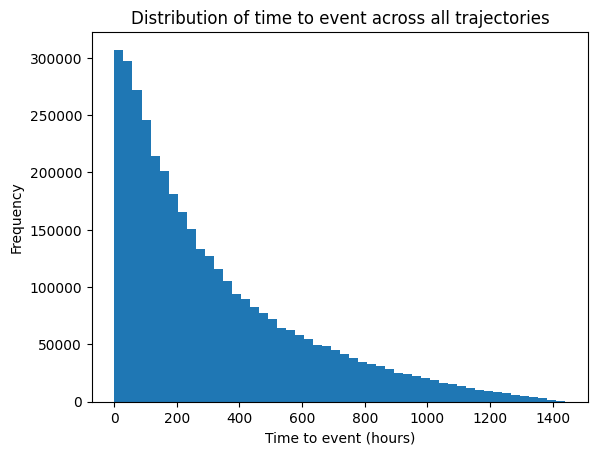

In [43]:
# plot histogram of time to event
plt.hist(time_to_event, bins=50)
plt.xlabel('Time to event (hours)')
plt.ylabel('Frequency')
plt.title('Distribution of time to event across all trajectories')
plt.show()

In [44]:
# create 8 time bins with equal occupancy from time_to_event, and print the bin edges
bin_edges = np.percentile(time_to_event, np.linspace(0, 100, 9))
print(f"Bin edges: {bin_edges}")

Bin edges: [1.00e+00 4.50e+01 9.40e+01 1.54e+02 2.30e+02 3.29e+02 4.72e+02 6.96e+02
 1.44e+03]


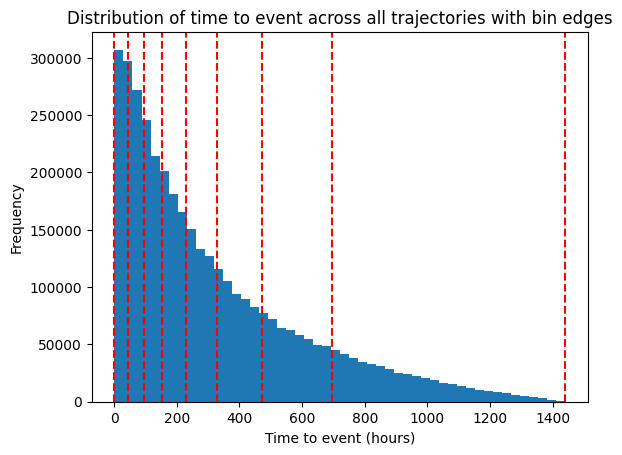

In [45]:
# plot a histogram of the time to event with the bin edges as vertical lines
plt.hist(time_to_event, bins=50)
for edge in bin_edges:
    plt.axvline(edge, color='red', linestyle='--')
plt.xlabel('Time to event (hours)')
plt.ylabel('Frequency')
plt.title('Distribution of time to event across all trajectories with bin edges')
plt.show()

In [46]:
# get the counts of time_to_event in each bin
bin_counts = np.histogram(time_to_event, bins=bin_edges)[0]
print(f"Bin counts: {bin_counts}")

Bin counts: [463243 466221 472118 472250 467597 470042 467878 469953]
